In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load shared POLDER style 
for _base in [Path.cwd(), *Path.cwd().parents]:
    _cand = _base / "templates" / "polder.mplstyle"
    if _cand.exists():
        plt.style.use(str(_cand))
        break

TEAL      = "#00A39B"   # stable equilibria / primary
DARK_TEAL = "#006661"   # axes, titles, equilibrium markers
CORAL     = "#E8633A"   # unstable / intervention / warning
BLUE      = "#0A4D9E"

print("ready")

ready


Set parameters and define rate of change f(X)=dX/dt and the potential function V(X) to create the landscape.

In [ ]:
"""
Input parameters
----------------
X = population density
K = carrying capacity
c = maximum harvest rate    c=1 for high resilience, c=2.6 for low resilience
"""

K=10
c_low=2.6
c_high=1

def f(X,K,c):
    """f(X)=dX/dt"""
    return X(1-X/K)-c(X**2/(X**2+1))

def V(X,K,c):
    """V(x)=-∫f(X)dX is the potential landscape"""
    return -(0.5*X**2 - (1.0/(3.0*K))*X**3 - c*(X - np.arctan(X))) #integral of f(X) which I let wolfram alpha calculate for me



Plot landscape functions, corresponding to figure 1.a and figure 1.d

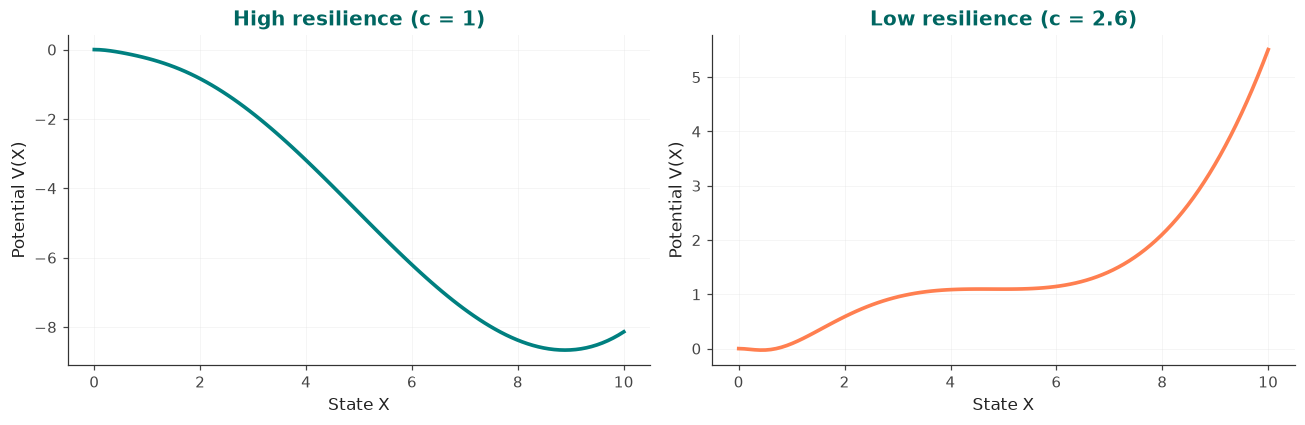

In [12]:
X = np.linspace(0,10,100)

V_high = V(X,K,c_high)
V_low = V(X,K,c_low)


#plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

#high resilience landscape
ax1.plot(X, V_high, color="TEAL", lw=2.4)
ax1.set_title("High resilience (c = 1)")
ax1.set_xlabel("State X")
ax1.set_ylabel("Potential V(X)")
ax1.grid(alpha=0.3)

#low resilience landscape
ax2.plot(X, V_low, color="CORAL", lw=2.4)
ax2.set_title("Low resilience (c = 2.6)")
ax2.set_xlabel("State X")
ax2.set_ylabel("Potential V(X)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()